# 02 · Acceleration utility: from the blocks to top speed

**Run order:** `01_globalization` → `02_acceleration_utility` → `03_top_speed_utility`. Each notebook runs on its own (kernel `anaconda3`) and writes no files.

Tests the acceleration detectors in `stride.py` on one runner, with the run summary from `sprint_summary.py`.
Every event is drawn as a skeleton so it can be checked by eye.

**Ground contact, the rule every event is built on** (`stride.foot_contacts`). A foot is on the ground when
its lower point (heel or toe landmark) is **within 3 cm of the local floor AND moving slower than 1.5 m/s**.
These are the two thresholds `sprint_report.py` already uses, required together. The local floor is a rolling
10th percentile over ±0.5 s, because the floor drifts 3–5 cm over 60 m and the toe dips 3 cm at every push-off.
On the block pedals the foot sits above the floor, so a foot that is still at frame 0 is on its pedal until it
first moves.

**Events** (Kinogram Notes sheet):

| event | definition |
|---|---|
| set position | frame 0: the last frame both hands are on the track (= first movement) |
| rear / front foot clearance | the foot's last frame on its pedal (= take-off from the block) |
| rear ankle cross | rear ankle passes the front knee |
| step *n* touchdown | the foot's first frame on the track |
| step *n* ankle cross | the swing ankle passes the stance knee |
| step *n* take-off | the foot's last frame on the track (= toe-off) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sprint_pipeline as SP          # landmark indices
import sprint_summary as SS           # the run in plain numbers (uses stride.py underneath)
import sprint_outputs as OUT          # skeleton drawing
import stride as ST                   # the event detectors under test

RUNNER = "SB80"

## 0 · The run at a glance (`sprint_summary.py`), in the order things happen

In [2]:
run = SS.summarize(RUNNER)
raw, fs = run.trial["raw64"], run.trial["fs"]
peak = int(np.argmax(run.speed))                      # top-speed frame: acceleration ends here
display(run.timeline)
pd.Series(run.headline)

,event,frame,time_s,distance_m,value
0,set position (first movement),0,0.000,0.00,None
1,rear foot (R) leaves block,4,0.067,0.09,None
2,front foot (L) leaves block,17,0.283,0.54,None
3,step 1 touchdown (R),18,0.300,0.58,block flight 0.017 s
4,10 m,130,2.167,10.03,None
5,20 m,219,3.650,20.06,None
6,30 m,304,5.067,30.09,None
7,40 m,388,6.467,40.03,None
9,top speed,463,7.717,48.95,7.14 m/s after 32 steps
8,50 m,472,7.867,50.01,None


runner                      SB80
time_to_60m_s              9.333
top_speed_ms                7.14
time_to_top_speed_s        7.717
distance_at_top_speed_m     48.9
steps_to_top_speed            32
steps_to_60m                  38
avg_stride_length_m         3.22
avg_stride_frequency_hz     2.08
avg_step_frequency_hz       4.15
block_time_s               0.283
missed_contacts                0
dtype: object

## 1 · Ground contacts in the first 1.5 s

The black line is the lower of heel and toe. Shaded = on the ground (orange = block pedal, blue = track).

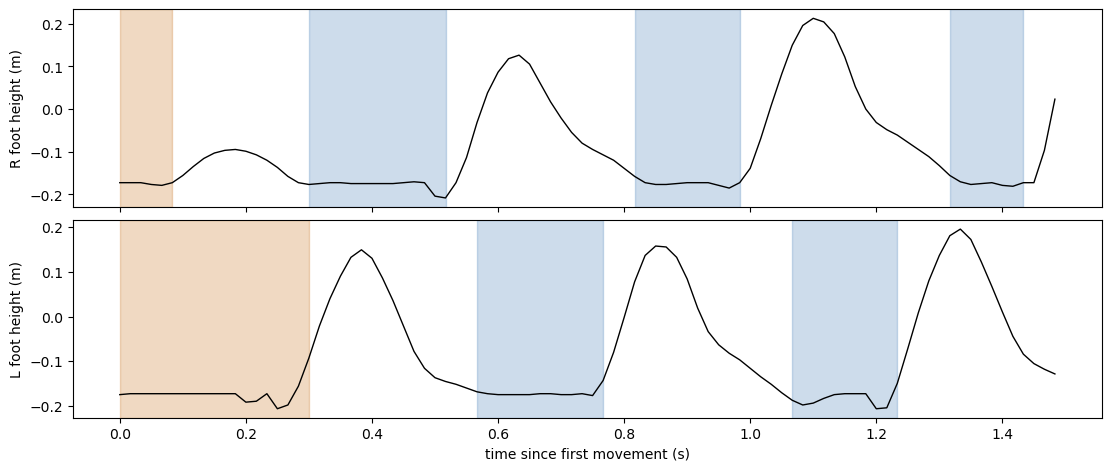

In [3]:
first = slice(0, int(1.5 * fs))
time = np.arange(len(raw)) / fs
fig, ax = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, constrained_layout=True)
for row, foot in enumerate("RL"):
    lowest = raw[:, ST.FOOT[foot], SP._VERT].min(axis=1)
    ax[row].plot(time[first], lowest[first], color="k", lw=1)
    for c in run.contacts:
        if c.foot == foot and c.touchdown < first.stop:
            ax[row].axvspan(c.touchdown / fs, (c.take_off + 1) / fs, alpha=0.25,
                            color="#c7680f" if c.on_blocks else "#3a76b3")
    ax[row].set_ylabel(f"{foot} foot height (m)")
ax[1].set_xlabel("time since first movement (s)");

## 2 · Block start

From the set position to step 1 landing. Solid limbs = right side, faint = left.

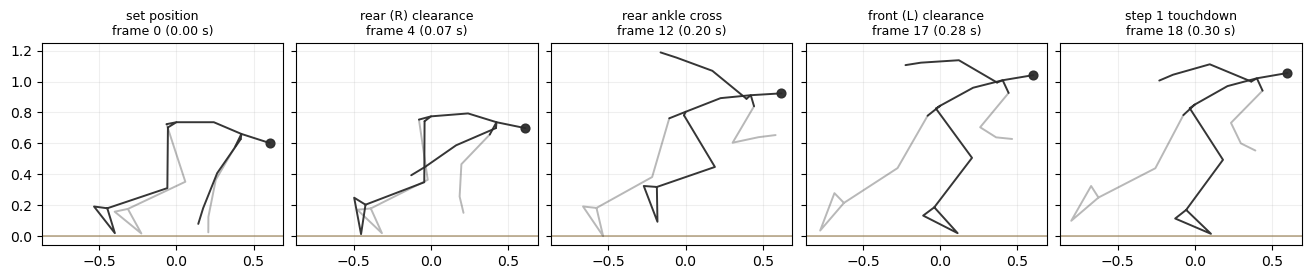

In [4]:
b = run.blocks
steps = ST.acceleration_steps(raw, run.contacts, until_frame=peak)
OUT.plot_event_strip(raw, [("set position", b.set_position),
                           (f"rear ({b.rear_foot}) clearance", b.rear_clearance),
                           ("rear ankle cross", b.rear_ankle_cross),
                           (f"front ({b.front_foot}) clearance", b.front_clearance),
                           ("step 1 touchdown", steps[0].touchdown)], fs);

## 3 · The first two steps out of the blocks: touchdown, ankle cross, take-off

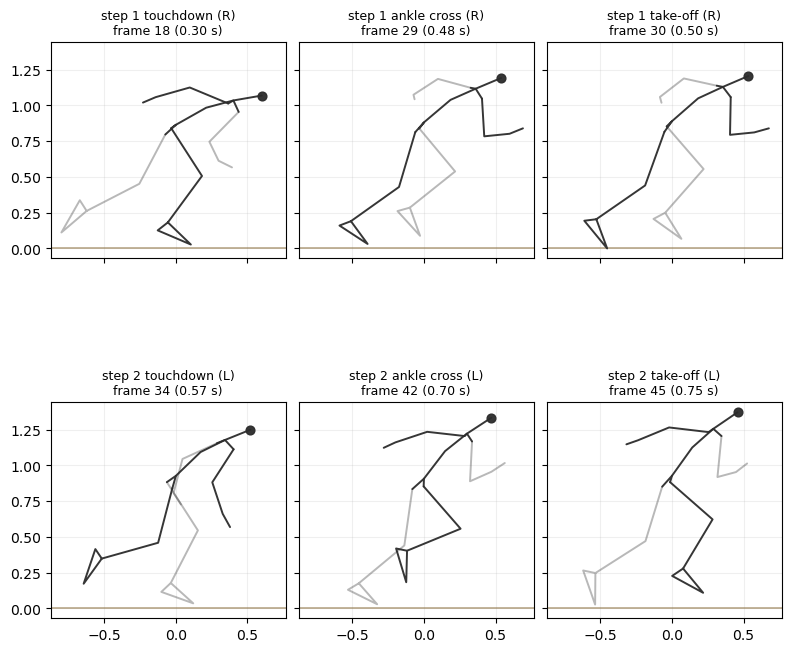

In [5]:
OUT.plot_event_strip(raw, [(f"step {s.number} {name} ({s.foot})", getattr(s, attr))
                           for s in steps[:2]
                           for name, attr in (("touchdown", "touchdown"), ("ankle cross", "ankle_cross"),
                                              ("take-off", "take_off"))], fs, ncols=3);

## 4 · Every step until top speed

Contact = touchdown to take-off. Flight = take-off to the next touchdown. Step length = pelvis travel between
touchdowns.

,foot,touchdown_s,ankle_cross_s,take_off_s,contact_ms,flight_ms,step_length_m,speed_ms
step,,,,,,,,
1,R,0.300,0.483,0.500,216.667,50.000,0.841,2.721
2,L,0.567,0.700,0.750,200.000,50.000,1.007,3.501
3,R,0.817,0.950,0.967,166.667,83.333,1.177,4.213
4,L,1.067,1.183,1.217,166.667,83.333,1.302,4.839
5,R,1.317,1.417,1.417,116.667,100.000,1.202,5.352
6,L,1.533,1.633,1.683,166.667,83.333,1.474,5.704
7,R,1.783,1.900,1.917,150.000,116.667,1.677,6.031
8,L,2.050,2.117,2.133,100.000,100.000,1.275,6.290
9,R,2.250,2.350,2.367,133.333,116.667,1.647,6.436


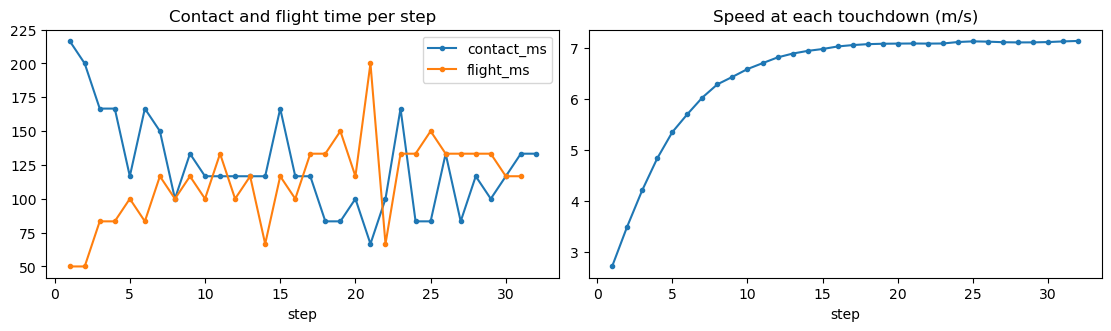

In [6]:
rows = []
for s, nxt in zip(steps, steps[1:] + [None]):
    rows.append({"step": s.number, "foot": s.foot,
                 "touchdown_s": s.touchdown / fs,
                 "ankle_cross_s": np.nan if s.ankle_cross is None else s.ankle_cross / fs,
                 "take_off_s": s.take_off / fs,
                 "contact_ms": (s.take_off - s.touchdown + 1) / fs * 1000,
                 "flight_ms": (nxt.touchdown - s.take_off - 1) / fs * 1000 if nxt else np.nan,
                 "step_length_m": run.distance[nxt.touchdown] - run.distance[s.touchdown] if nxt else np.nan,
                 "speed_ms": run.speed[s.touchdown]})
accel = pd.DataFrame(rows).round(3).set_index("step")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
accel[["contact_ms", "flight_ms"]].plot(ax=ax[0], marker="o", ms=3, title="Contact and flight time per step")
accel["speed_ms"].plot(ax=ax[1], marker="o", ms=3, title="Speed at each touchdown (m/s)")
accel

**Reading the zig-zag.** At 60 Hz every contact and flight time is a whole number of 16.7 ms frames, so a
real 100 ms contact reads as 83 or 117 ms depending on where the frames fall. Mid-run, right and left contacts
also alternate short and long, which points at the Xsens foot model rather than the runner. Compare runners on
averages over several steps, not on single steps.

## 5 · Self-checks

In [7]:
feet = [s.foot for s in steps]
assert all(a != b for a, b in zip(feet, feet[1:])), "steps must alternate feet"
assert b.set_position < b.rear_clearance < b.front_clearance < steps[0].touchdown, "block events out of order"
for s, nxt in zip(steps, steps[1:]):
    assert s.touchdown <= s.take_off < nxt.touchdown, f"step {s.number}: take-off after next touchdown"
    assert s.ankle_cross is None or s.touchdown <= s.ankle_cross < nxt.touchdown
assert accel.contact_ms.between(30, 300).all(), "a contact time is outside 30-300 ms"
assert steps[-1].touchdown <= peak
print(f"acceleration checks passed: {len(steps)} steps, block exit to top speed")

acceleration checks passed: 32 steps, block exit to top speed
